# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: siraj eddine nedjai    Group: 2    Date: 04/11/2026

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [37]:
np.random.seed(42)

years_of_experience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

salary = intercept + slope * years_of_experience + noise

df = pd.DataFrame({
    'YearsOfExperience': years_of_experience,
    'Salary': salary
})

print("DataFrame shape:", df.shape)
print(df.head())

DataFrame shape: (500, 2)
   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [38]:
print("Shape:", df.shape)

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

correlation = df['YearsOfExperience'].corr(df['Salary'])
print(f"\nCorrelation between YearsOfExperience and Salary: {correlation:.4f}")

Shape: (500, 2)

Summary Statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204

Missing Values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation between YearsOfExperience and Salary: 0.9751


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

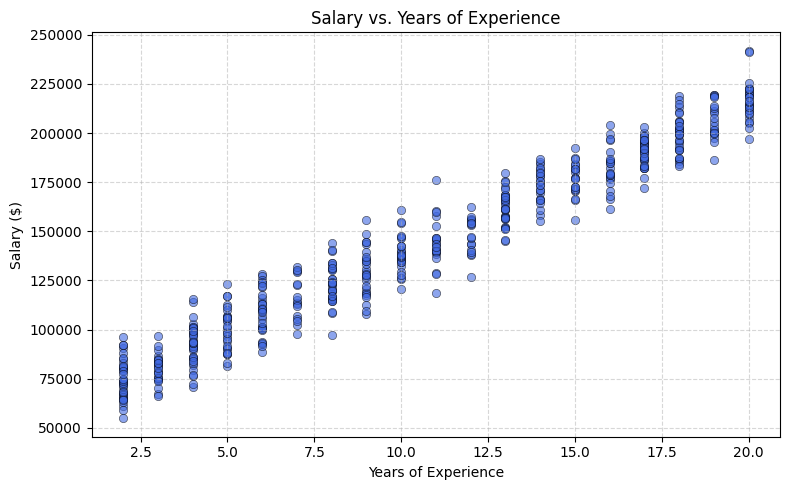

In [39]:
plt.figure(figsize=(8, 5))
plt.scatter(df['YearsOfExperience'], df['Salary'], alpha=0.6, color='royalblue', edgecolor='k', linewidth=0.5)

plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.title('Salary vs. Years of Experience')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [40]:
X = df[['YearsOfExperience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Number of training records: {X_train.shape[0]}")
print(f"Number of test records: {X_test.shape[0]}")

Number of training records: 400
Number of test records: 100


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [41]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"mae:  {mae}")
print(f"mse:  {mse}")
print(f"rmse: {rmse}")
print(f"r2:   {r2}")

mae:  7905.114728709239
mse:  93933277.37947103
rmse: 9691.918147584152
r2:   0.9573704756930141


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [42]:
baseline_pred = np.full_like(y_test, fill_value=y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)

print(f"baseline mae:  {baseline_mae}")
print(f"baseline rmse: {baseline_rmse}")

baseline mae:  40444.95787424255
baseline rmse: 46953.769510036946


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

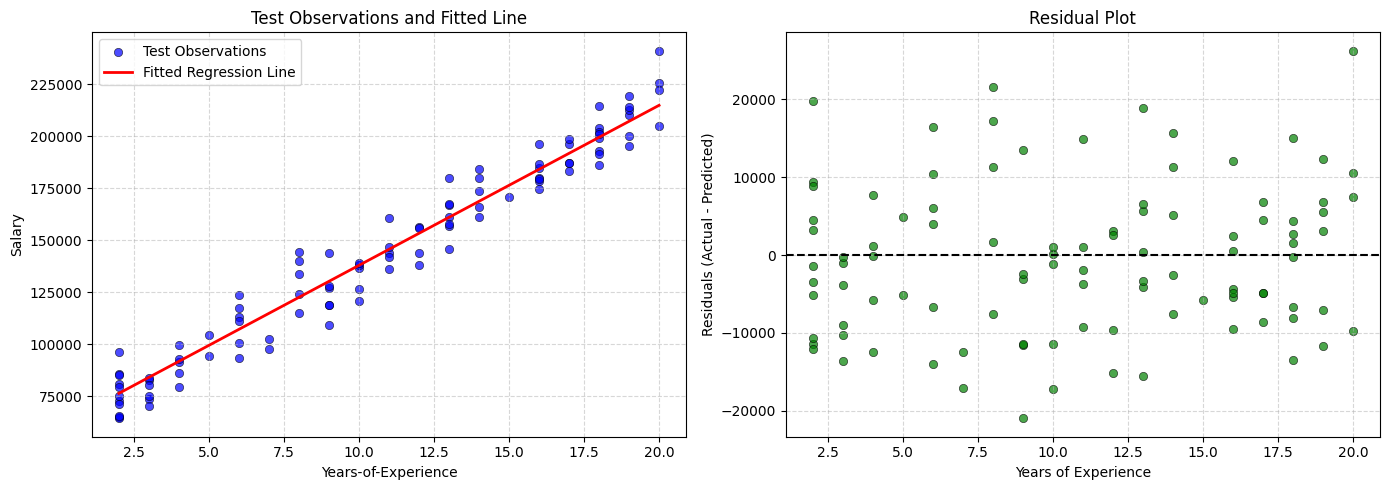

In [43]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_test, y_test, color='blue', alpha=0.7, edgecolor='k', linewidth=0.5, label='Test Observations')

sorted_idx = np.argsort(X_test['YearsOfExperience'])
X_test_sorted = X_test.iloc[sorted_idx]
y_pred_sorted = y_pred[sorted_idx]

axes[0].plot(X_test_sorted, y_pred_sorted, color='red', linewidth=2, label='Fitted Regression Line')
axes[0].set_xlabel('Years-of-Experience')
axes[0].set_ylabel('Salary')
axes[0].set_title('Test Observations and Fitted Line')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(X_test, residuals, color='green', alpha=0.7, edgecolor='k', linewidth=0.5)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Years of Experience')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].set_title('Residual Plot')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [44]:
new_experience = pd.DataFrame({'YearsOfExperience': [5, 10, 15]})

predicted_salaries = model.predict(new_experience)

results_df = pd.DataFrame({
    'Years of Experience': [5, 10, 15],
    'Predicted Salary': predicted_salaries
})

print(results_df)

   Years of Experience  Predicted Salary
0                    5      99444.405496
1                   10     137927.470111
2                   15     176410.534726


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [45]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print(f"X_train scaled mean: {X_train_scaled.mean()}, std: {X_train_scaled.std()}")
print(f"X_test scaled mean:  {X_test_scaled.mean()}, std: {X_test_scaled.std()}")

X_train scaled mean: 1.4210854715202004e-16, std: 1.0
X_test scaled mean:  0.03651447513752358, std: 1.037254533918594


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [46]:
ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_train_scaled, y_train)
y_pred_10 = ridge_10.predict(X_test_scaled)

coef_10 = ridge_10.coef_[0]
mae_10 = mean_absolute_error(y_test, y_pred_10)
r2_10 = r2_score(y_test, y_pred_10)

ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_train_scaled, y_train)
y_pred_100 = ridge_100.predict(X_test_scaled)

coef_100 = ridge_100.coef_[0]
mae_100 = mean_absolute_error(y_test, y_pred_100)
r2_100 = r2_score(y_test, y_pred_100)

print(f"Alpha = 10:  Coefficient = {coef_10:.4f}, Test mae = {mae_10:.2f}, Test R2 = {r2_10:.4f}")
print(f"Alpha = 100: Coefficient = {coef_100:.4f}, Test mae = {mae_100:.2f}, Test R2 = {r2_10:.4f}")

Alpha = 10:  Coefficient = 42156.5031, Test mae = 8084.46, Test R2 = 0.9557
Alpha = 100: Coefficient = 34568.3325, Test mae = 11308.37, Test R2 = 0.9557


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [47]:
alphas = [1000, 10000, 50000]
lasso_models = {}

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=20000)
    lasso.fit(X_train_scaled, y_train)

    lasso_models[alpha] = lasso

    y_pred = lasso.predict(X_test_scaled)

    coef = lasso.coef_[0]
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Alpha = {alpha:<5}: Coefficient = {coef:10.4f}, Test mae = {mae:8.2f}, Test R2 = {r2:7.4f}")

lasso_1000 = lasso_models[1000]

Alpha = 1000 : Coefficient = 42210.4157, Test mae =  8074.65, Test R2 =  0.9558
Alpha = 10000: Coefficient = 33210.4157, Test mae = 12287.96, Test R2 =  0.8980
Alpha = 50000: Coefficient =     0.0000, Test mae = 40444.96, Test R2 = -0.0005


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [48]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

y_pred_lasso_1000 = lasso_1000.predict(X_test_scaled)

models_performance = {
    'Mean Baseline': evaluate_model(y_test, baseline_pred),
    'Linear Regression': evaluate_model(y_test, y_pred),
    'Ridge (alpha=10)': evaluate_model(y_test, y_pred_10),
    'Lasso (alpha=1000)': evaluate_model(y_test, y_pred_lasso_1000)
}

summary_df = pd.DataFrame(models_performance, index=['Test MAE', 'Test RMSE', 'Test R2']).T
print(summary_df)

                        Test MAE     Test RMSE   Test R2
Mean Baseline       40444.957874  46953.769510 -0.000534
Linear Regression   40444.957874  46953.769510 -0.000534
Ridge (alpha=10)     8084.461348   9876.931577  0.955727
Lasso (alpha=1000)   8074.651463   9864.608230  0.955838


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.